# Covariance Denoising for Equity Portfolios

*Does removing random-matrix noise from a stock correlation matrix produce lower-risk portfolios out of sample?*

Denoising works when data are scarce and backfires when they are not. With a 6-month estimation window it cuts the realised volatility of a minimum-variance portfolio from 21.0% to 13.4%; with a 2-year window it raises it from 14.1% to 16.4%, because the noise cut-off throws away real sector structure. Smooth Ledoit-Wolf shrinkage is the most reliable choice across every window (13.3–13.7%).

| Question | Finding | Section |
|---|---|---|
| Is the noise benchmark implemented correctly? | Simulated eigenvalue edges match the Marcenko-Pastur bounds for q = 2 to 20 (q = 10: theory 0.47–1.73, simulated 0.46–1.74). | 1 |
| How much of a 90-stock correlation matrix is signal? | 7 eigenvalues sit above the fitted noise edge and explain 50% of variance. The fit is pinned at its σ² = 1 bound, and a trace-preserving fit admits 35, so the signal count is not well identified. | 2 |
| What do the leading factors represent? | PC1 is the market (20% of variance), PC2 defensive vs cyclical sectors, PC3 Energy. | 2 |
| What does cleaning do to the matrix? | Condition number 197 → 43 (constant residual). Detoning moves average cross-sector correlation from +0.16 to −0.04. | 3 |
| Does denoising help when the true covariance is known? | Yes. Min-variance risk is 41% above optimal with the sample matrix, 24% with Ledoit-Wolf and 10% denoised (q = 2). | 4 |
| Does it help on real stocks? | No. Not with a 2-year window: out-of-sample volatility 16.4% denoised vs 14.1% sample and 13.7% Ledoit-Wolf (unconstrained, 2017–2026). | 5 |
| Why does the real-data result reverse? | The noise cut-off discards real sector structure. Keeping 20–30 factors matches the sample matrix; keeping 7 costs about 0.9 pp of volatility. | 6 |
| Is any benefit left? | Denoised weights trade 40% less (turnover 0.27 vs 0.45 per rebalance). | 7 |
| Does denoising help when the estimation window is short? | Yes. With 126 days (q = 1.4) it cuts volatility from 21.0% to 13.4%, level with Ledoit-Wolf (13.3%), and turnover from 3.5 to 0.7 per rebalance. The benefit is gone by 252 days and reverses at 504. | 8 |

**Use it when.** A covariance matrix feeds an optimiser (minimum variance, mean-variance, risk parity) and the sample is short relative to the number of assets, or before clustering assets, where detoning exposes sector structure.

**Method.** Fit the Marcenko-Pastur noise band to the correlation eigenvalues, keep the eigenvalues above the band, flatten the rest (constant residual) or shrink only their off-diagonal part (targeted), and optionally remove the market eigenvector (detoning).

**Data.** Daily adjusted closes for 90 US large-cap stocks in 10 sectors, Jan-2015 to Oct-2026 (2,973 daily returns, Yahoo Finance), simple daily returns. Sector labels follow a GICS-like mapping. The list holds today's large caps, so returns carry survivorship bias; estimators are compared against each other on the same data.

**Contents.** 1 Noise benchmark · 2 Real spectrum · 3 Cleaning the matrix · 4 Known-truth test · 5 Out-of-sample test · 6 How many factors · 7 Weight stability · 8 Short estimation windows · Conclusions

In [1]:
import sys, warnings
sys.path.insert(0, ".")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.covariance import LedoitWolf

import data_utils as du
import quant_tools as qt

du.set_style()
np.random.seed(7)

In [2]:
returns = du.load_returns("stocks", log=False)
sector = pd.Series(du.sector_map())[returns.columns].astype(object)
print(f"{returns.shape[1]} stocks, {returns.shape[0]} daily returns, {returns.index[0].date()} to {returns.index[-1].date()}")
print(sector.value_counts().to_string())

Downloaded 91 of 91 tickers: {'Yahoo chart API': 91}
90 stocks, 2973 daily returns, 2015-01-05 to 2026-10-29
Tech             12
Health           11
Financials       11
Staples          10
Industrials      10
Discretionary     9
Comm              8
Energy            8
Utilities         6
Materials         5


## 1 · Is the noise benchmark right?

If N assets were pure noise observed T times, the eigenvalues of their correlation matrix would fall inside a band whose edges depend only on q = T/N:
λ± = σ²(1 ± √(1/q))².
Any eigenvalue above λ+ carries structure the noise cannot produce. The closed form is checked against brute-force simulations of pure noise.

 q = T/N  theory λ-  sim min  theory λ+  sim max
       2      0.086    0.081      2.914    3.066
       5      0.306    0.288      2.094    2.124
      10      0.468    0.458      1.732    1.739
      20      0.603    0.589      1.497    1.511


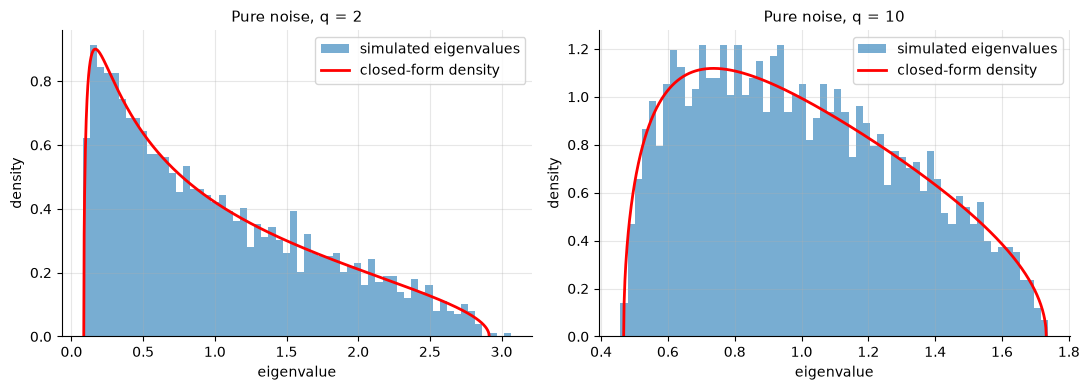

In [3]:
def simulate_noise_eigs(T, N, n_rep=20):
    out = []
    for _ in range(n_rep):
        x = np.random.randn(T, N)
        out.append(np.linalg.eigvalsh(np.corrcoef(x, rowvar=False)))
    return np.concatenate(out)

rows, fig_data = [], {}
for q in [2, 5, 10, 20]:
    N = 100
    eig = simulate_noise_eigs(q * N, N)
    lo, hi = (1 - (1 / q) ** 0.5) ** 2, (1 + (1 / q) ** 0.5) ** 2
    rows.append({"q = T/N": q, "theory λ-": lo, "sim min": eig.min(), "theory λ+": hi, "sim max": eig.max()})
    fig_data[q] = eig
print(pd.DataFrame(rows).round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, q in zip(axes, [2, 10]):
    ax.hist(fig_data[q], bins=60, density=True, alpha=0.6, label="simulated eigenvalues")
    pdf = qt.mp_pdf(1.0, q)
    ax.plot(pdf.index, pdf.values, "r", lw=2, label="closed-form density")
    ax.set(title=f"Pure noise, q = {q}", xlabel="eigenvalue", ylabel="density")
    ax.legend()
plt.tight_layout(); plt.show()

- Simulated minimum and maximum eigenvalues land on the closed-form edges for every q. The largest overshoot is 5% at q = 2, a finite-N effect (N = 100).
- At q = 2, noise alone spreads eigenvalues from 0.09 to 2.9. A sample matrix built from this little data looks structured by chance.
- The band narrows as q grows, so noise matters most when the sample is short relative to the number of assets.

## 2 · How much of the equity matrix is signal?

The last three years (756 days) of the 90 stocks give q ≈ 8.4. The noise variance σ² is fitted two ways: by matching a kernel density of the eigenvalues to the Marcenko-Pastur curve, and by a trace-preserving fixed point that forces the bulk eigenvalues to average σ². The gap between the two shows how firm the signal/noise cut-off is.

T = 756, N = 90, q = 8.4
                  σ² (noise var)  λ+ (upper edge)  signal eigenvalues
KDE match                  0.999            1.807                   7
trace preserving           0.332            0.600                  35


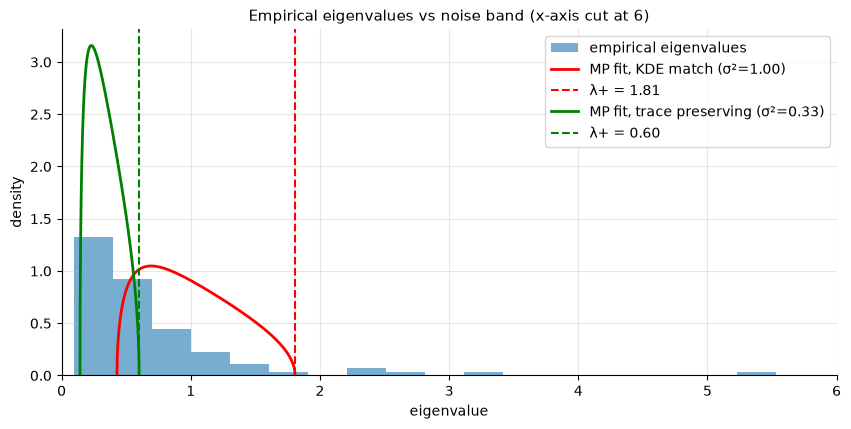

      eigenvalue  % of total variance  above λ+
PC1        18.23                20.26      True
PC2        10.69                11.88      True
PC3         5.41                 6.01      True
PC4         3.37                 3.74      True
PC5         2.78                 3.09      True
PC6         2.50                 2.78      True
PC7         2.21                 2.46      True
PC8         1.70                 1.89     False
PC9         1.60                 1.77     False
PC10        1.47                 1.64     False


In [4]:
WINDOW = 756
window = returns.iloc[-WINDOW:]
T, N = window.shape
q = T / N
corr = window.corr().values
eig, vec = qt.get_pca(corr)

e_max_kde, var_kde = qt.fit_mp(eig, q)
e_max_trace, var_trace = qt.fit_mp_trace(eig, q)
n_sig_kde, n_sig_trace = int((eig > e_max_kde).sum()), int((eig > e_max_trace).sum())

fit_table = pd.DataFrame({
    "σ² (noise var)": [var_kde, var_trace],
    "λ+ (upper edge)": [e_max_kde, e_max_trace],
    "signal eigenvalues": [n_sig_kde, n_sig_trace],
}, index=["KDE match", "trace preserving"]).round(3)
print(f"T = {T}, N = {N}, q = {q:.1f}")
print(fit_table.to_string())

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(eig, bins=60, density=True, alpha=0.6, label="empirical eigenvalues")
pdf = qt.mp_pdf(var_kde, q)
ax.plot(pdf.index, pdf.values, "r", lw=2, label=f"MP fit, KDE match (σ²={var_kde:.2f})")
ax.axvline(e_max_kde, color="r", ls="--", label=f"λ+ = {e_max_kde:.2f}")
pdf_t = qt.mp_pdf(var_trace, q)
ax.plot(pdf_t.index, pdf_t.values, "g", lw=2, label=f"MP fit, trace preserving (σ²={var_trace:.2f})")
ax.axvline(e_max_trace, color="g", ls="--", label=f"λ+ = {e_max_trace:.2f}")
ax.set(xlim=(0, 6), title="Empirical eigenvalues vs noise band (x-axis cut at 6)",
       xlabel="eigenvalue", ylabel="density")
ax.legend(); plt.show()

top = pd.DataFrame({"eigenvalue": eig[:10], "% of total variance": 100 * eig[:10] / N,
                    "above λ+": eig[:10] > e_max_kde}).round(2)
top.index = [f"PC{i+1}" for i in range(10)]
print(top.to_string())

- Seven of 90 eigenvalues exceed the density-fitted edge (λ+ = 1.81). The first explains 20% of total variance and the first seven 50%.
- The density fit ends at its upper bound (σ² = 1) and the curve misses the bulk: many eigenvalues lie below the theoretical lower edge of 0.43. Equity returns have fat tails and volatility clustering, so the bulk is not Marcenko-Pastur noise.
- The trace-preserving fit follows the bulk better (σ² = 0.33) but admits 35 signal eigenvalues. The true count lies somewhere between 7 and 35, and section 6 settles it out of sample.

### What do the leading eigenvectors represent?
Average loadings per sector: a market factor loads every sector with the same sign; the next factors should set sectors against each other.

                 PC1    PC2    PC3    PC4
Comm           0.081  0.019 -0.021  0.097
Discretionary  0.113 -0.010 -0.069  0.081
Energy         0.093 -0.021  0.309  0.069
Financials     0.158 -0.089 -0.005 -0.089
Health         0.088  0.077 -0.030  0.020
Industrials    0.115 -0.016 -0.010 -0.079
Materials      0.111 -0.004 -0.031 -0.057
Staples        0.079  0.157 -0.039  0.083
Tech           0.081 -0.098 -0.038  0.074
Utilities      0.079  0.175  0.010 -0.164


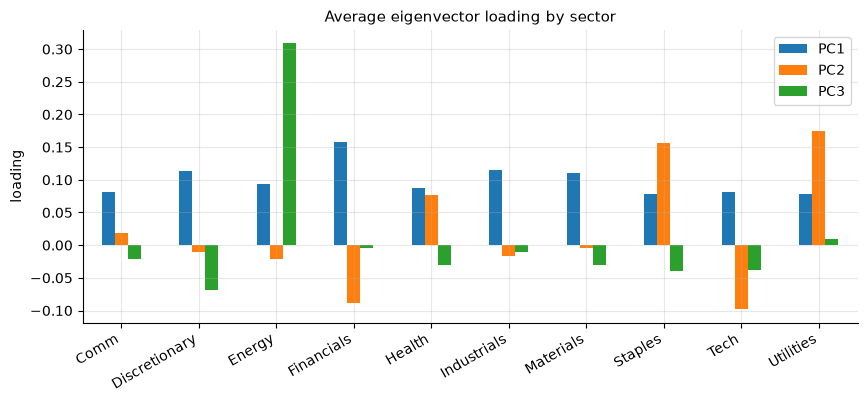

In [5]:
loadings = pd.DataFrame(vec[:, :4], index=returns.columns, columns=[f"PC{i+1}" for i in range(4)])
loadings = loadings * np.sign(loadings.sum())  # fix sign so PC1 is positive
by_sector = loadings.groupby(sector).mean().round(3)
print(by_sector.to_string())

fig, ax = plt.subplots(figsize=(10, 3.8))
by_sector[["PC1", "PC2", "PC3"]].plot.bar(ax=ax)
ax.set(title="Average eigenvector loading by sector", ylabel="loading", xlabel="")
plt.xticks(rotation=30, ha="right"); plt.show()

- PC1 loads positively on every sector: the market factor. Financials load most (0.16).
- PC2 is a defensive-versus-cyclical axis: Utilities (+0.18), Staples (+0.16) and Health (+0.08) against Tech (−0.10) and Financials (−0.09).
- PC3 is Energy alone (+0.31), an oil factor. The remaining signal eigenvalues are smaller sector effects.

## 3 · What does cleaning do to the matrix?

Two ways to remove the noise eigenvectors while keeping the 7 signal ones:
1. **Constant residual**: replace every noise eigenvalue by their average (trace preserved).
2. **Targeted shrinkage** (α = 0): remove the off-diagonal part of the noise component only.

Detoning removes the market eigenvector on top. The matrices are compared by condition number (largest / smallest eigenvalue, a measure of how much an inverse amplifies errors) and by the average correlation inside versus across sectors.

                     condition number  within-sector ρ  across-sector ρ    gap
sample                        196.943            0.389            0.156  0.233
denoised (const)               43.114            0.346            0.160  0.186
denoised (targeted)           108.967            0.386            0.162  0.224
detoned                           NaN            0.240           -0.036  0.276
denoised + detoned                NaN            0.184           -0.030  0.215


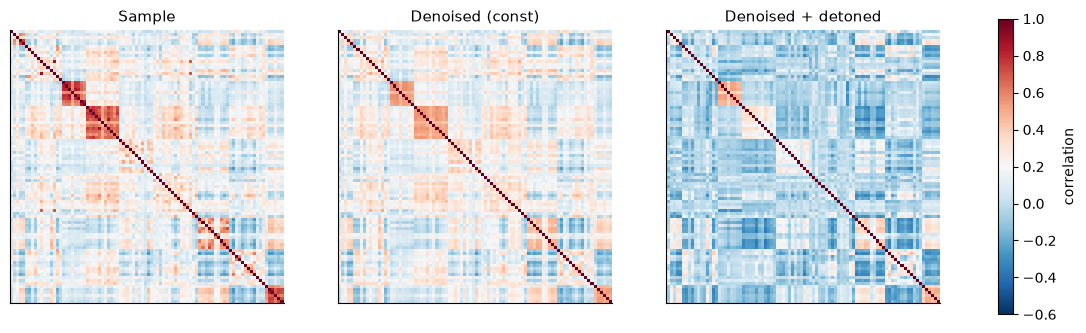

In [6]:
n_facts = n_sig_kde
corr_const = qt.denoise_const_resid(eig, vec, n_facts)
corr_target = qt.cov2corr(qt.denoise_targeted(eig, vec, n_facts, alpha=0.0))
corr_detone = qt.detone_corr(corr, 1)
corr_dn_dt = qt.detone_corr(corr_const, 1)

def block_stats(c):
    same = (sector.values[:, None] == sector.values[None, :]) & ~np.eye(N, dtype=bool)
    diff = sector.values[:, None] != sector.values[None, :]
    return c[same].mean(), c[diff].mean()

rows = {}
for name, c in [("sample", corr), ("denoised (const)", corr_const), ("denoised (targeted)", corr_target),
                ("detoned", corr_detone), ("denoised + detoned", corr_dn_dt)]:
    within, across = block_stats(c)
    singular = name in ("detoned", "denoised + detoned")  # removing a factor makes the matrix rank-deficient
    rows[name] = {"condition number": np.nan if singular else np.linalg.cond(c), "within-sector ρ": within,
                  "across-sector ρ": across, "gap": within - across}
stats = pd.DataFrame(rows).T.round(3)
print(stats.to_string())

order = sector.sort_values().index
idx = [list(returns.columns).index(t) for t in order]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, (name, c) in zip(axes, [("Sample", corr), ("Denoised (const)", corr_const), ("Denoised + detoned", corr_dn_dt)]):
    im = ax.imshow(c[np.ix_(idx, idx)], cmap="RdBu_r", vmin=-0.6, vmax=1)
    ax.set_title(name); ax.grid(False)
    ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes, shrink=0.8, label="correlation")
plt.show()

- Constant-residual denoising cuts the condition number from 197 to 43 (targeted shrinkage: 109), so the inverse reacts far less to input errors. Detoned matrices are rank-deficient by construction and have no finite condition number.
- Constant-residual denoising also flattens real sector structure: the within-minus-across gap falls from 0.233 to 0.186. Targeted shrinkage keeps it (0.224) because it touches only the noise off-diagonals.
- Detoning removes the market: average cross-sector correlation goes from +0.16 to −0.04 and the gap widens to 0.276, so sector blocks stand out (third heatmap). This suits clustering. It does not suit optimisation, because market risk is real risk.

## 4 · Does denoising help when the truth is known?

A known covariance removes the guesswork: 100 assets in 10 blocks (within-block ρ = 0.5) with volatilities between 10% and 35%. Each of 200 draws has T = 200 observations (q = 2). The covariance is estimated four ways, minimum-variance weights are built from each estimate, and their risk is measured with the true matrix. The ratio to the best achievable risk is the cost of estimation error.

                     true vol / optimal vol (mean)  worst of 200  weight RMSE vs optimal
sample                                       1.409         1.631                   0.021
ledoit-wolf                                  1.240         1.349                   0.015
denoised (const)                             1.102         1.184                   0.009
denoised (targeted)                          1.106         1.187                   0.009


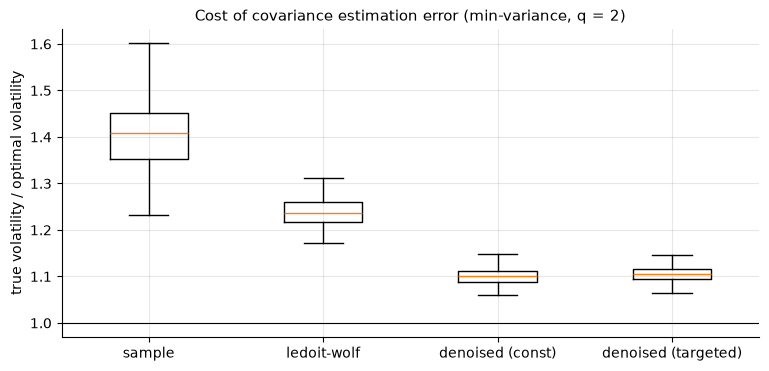

In [7]:
def block_cov(n_blocks=10, size=10, rho=0.5, rng=None):
    n = n_blocks * size
    corr = np.full((n, n), 0.0)
    for b in range(n_blocks):
        sl = slice(b * size, (b + 1) * size)
        corr[sl, sl] = rho
    np.fill_diagonal(corr, 1.0)
    vol = rng.uniform(0.10, 0.35, n)
    return corr * np.outer(vol, vol), vol

def estimate(sample, method):
    n, t = sample.shape[1], len(sample)
    cov = np.cov(sample, rowvar=False)
    if method == "sample":
        return cov
    if method == "ledoit-wolf":
        return LedoitWolf().fit(sample).covariance_
    std = np.sqrt(np.diag(cov))
    corr_s = qt.cov2corr(cov)
    ev, evec = qt.get_pca(corr_s)
    e_max, _ = qt.fit_mp(ev, t / n)
    k = int((ev > e_max).sum())
    c = qt.denoise_const_resid(ev, evec, k) if method == "denoised (const)" else qt.cov2corr(qt.denoise_targeted(ev, evec, k, 0.0))
    return qt.corr2cov(c, std)

rng = np.random.default_rng(1)
true_cov, _ = block_cov(rng=rng)
w_opt = qt.min_var_weights(true_cov)
opt_vol = np.sqrt(w_opt @ true_cov @ w_opt)
methods = ["sample", "ledoit-wolf", "denoised (const)", "denoised (targeted)"]
res = {m: [] for m in methods}
wdist = {m: [] for m in methods}
for _ in range(200):
    sample = rng.multivariate_normal(np.zeros(len(true_cov)), true_cov, size=200)
    for m in methods:
        w = qt.min_var_weights(estimate(sample, m))
        res[m].append(np.sqrt(w @ true_cov @ w) / opt_vol)
        wdist[m].append(np.sqrt(np.mean((w - w_opt) ** 2)))
mc_table = pd.DataFrame({
    "true vol / optimal vol (mean)": {m: np.mean(v) for m, v in res.items()},
    "worst of 200": {m: np.max(v) for m, v in res.items()},
    "weight RMSE vs optimal": {m: np.mean(v) for m, v in wdist.items()},
}).round(3)
print(mc_table.to_string())

fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot([res[m] for m in methods], tick_labels=methods, showfliers=False)
ax.axhline(1, color="k", lw=0.8)
ax.set(ylabel="true volatility / optimal volatility", title="Cost of covariance estimation error (min-variance, q = 2)")
plt.show()

- At q = 2 the sample covariance gives portfolios 41% riskier than the optimum (worst draw 63%). Ledoit-Wolf cuts the penalty to 24%; both denoised matrices to about 10% (worst draw 18%).
- Weight error falls from 0.021 (sample) to 0.015 (Ledoit-Wolf) and 0.009 (denoised), and the denoised estimates have the smallest spread across draws.
- When the truth is a few clean blocks plus Gaussian noise, denoising lowers the true risk of the optimised portfolio and beats the standard shrinkage baseline. Real returns are not Gaussian blocks, which is what the next sections test.

## 5 · Does it help on real stocks?

Rolling test: every 21 trading days the covariance is estimated on the previous 504 days (q ≈ 5.6), minimum-variance weights are built and held for the next 21 days. Unconstrained (closed form, shorting allowed) and long-only versions are run, with equal weight as the benchmark. Weights are reset to target daily within each holding window; no costs.

Out-of-sample: 2017-01-04 to 2026-10-29, 118 rebalances
                                 ann_return  ann_vol  sharpe  max_dd  avg gross leverage
unconstrained: sample                 0.044    0.141   0.311  -0.318               3.537
unconstrained: ledoit-wolf            0.054    0.137   0.393  -0.284               2.978
unconstrained: denoised (const)       0.039    0.164   0.236  -0.419               2.791
long-only: sample                     0.091    0.138   0.657  -0.308               1.000
long-only: ledoit-wolf                0.092    0.138   0.666  -0.308               1.000
long-only: denoised (const)           0.077    0.149   0.519  -0.361               1.000
equal weight                          0.167    0.172   0.972  -0.350               1.000


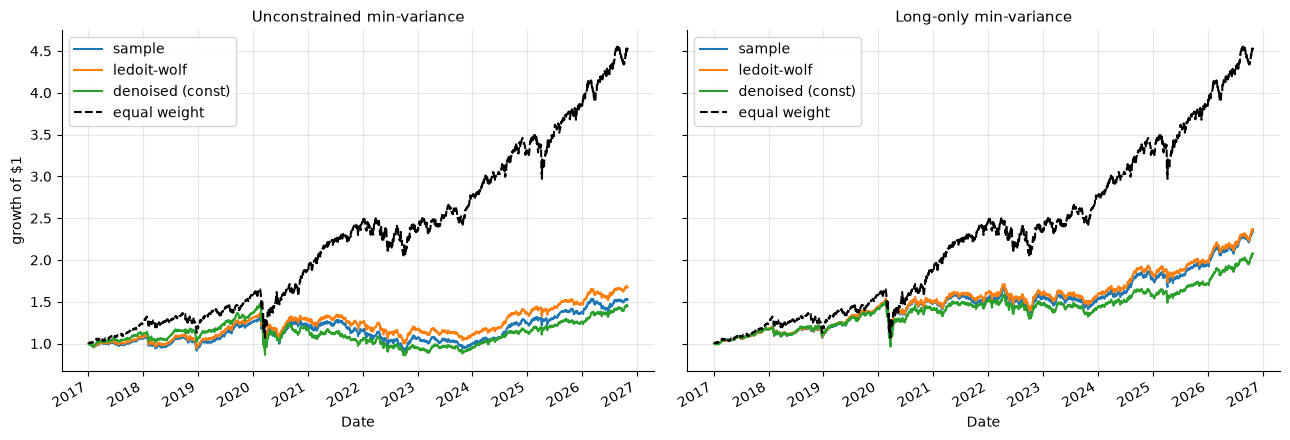

In [8]:
LOOKBACK, HOLD = 504, 21
rebal = list(range(LOOKBACK, len(returns) - 1, HOLD))

_cov_cache = {}

def cov_at(i, method):
    key = (i, method)
    if key not in _cov_cache:
        _cov_cache[key] = estimate(returns.iloc[i - LOOKBACK:i].values, method)
    return _cov_cache[key]

def run_backtest(methods, long_only):
    daily = {m: [] for m in methods}
    gross = {m: [] for m in methods}
    for i in rebal:
        fwd = returns.iloc[i:i + HOLD]
        for m in methods:
            cov = cov_at(i, m)
            w = qt.min_var_long_only(cov) if long_only else qt.min_var_weights(cov)
            daily[m].append(fwd @ w)
            gross[m].append(np.abs(w).sum())
    return pd.DataFrame({m: pd.concat(v) for m, v in daily.items()}), pd.DataFrame(gross)

methods_bt = ["sample", "ledoit-wolf", "denoised (const)"]
ret_free, gross_free = run_backtest(methods_bt, long_only=False)
ret_lo, gross_lo = run_backtest(methods_bt, long_only=True)
ew = returns.loc[ret_free.index].mean(axis=1)

def summarise(df, label):
    t = pd.DataFrame({f"{label}: {c}": du.annual_stats(df[c]) for c in df}).T
    return t

summary = pd.concat([
    summarise(ret_free, "unconstrained"),
    summarise(ret_lo, "long-only"),
    pd.DataFrame({"equal weight": du.annual_stats(ew)}).T,
])
summary["avg gross leverage"] = list(gross_free.mean()) + list(gross_lo.mean()) + [1.0]
print(f"Out-of-sample: {ret_free.index[0].date()} to {ret_free.index[-1].date()}, {len(rebal)} rebalances")
print(summary.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, df, title in [(axes[0], ret_free, "Unconstrained min-variance"), (axes[1], ret_lo, "Long-only min-variance")]:
    (1 + df).cumprod().plot(ax=ax)
    (1 + ew).cumprod().plot(ax=ax, color="k", ls="--", label="equal weight")
    ax.set(title=title, ylabel="growth of $1"); ax.legend()
plt.tight_layout(); plt.show()

- With a 2-year window, denoising does not lower realised risk. Unconstrained volatility is 16.4% denoised against 14.1% sample and 13.7% Ledoit-Wolf; long-only 14.9% against 13.8% for both. The known-truth ranking reverses.
- Denoising lowers the leverage of the unconstrained portfolio (2.8× against 3.5× for sample), but the structure it removes was carrying real risk information.
- Every minimum-variance portfolio has lower volatility than equal weight (17.2%), as designed, but far lower return (4–9% against 16.7%), so Sharpe is lower too. One decade of a rising market is a hint about returns, not proof.

## 6 · How many factors should be kept?

The noise band says 7. Since the bulk of the real spectrum is not a clean noise band, the choice is tested directly: at each rebalance the first k eigenvectors are kept, the rest flattened to their average, and the out-of-sample volatility of the minimum-variance portfolio is measured. k = 90 reproduces the sample matrix.

              unconstrained  long-only
factors kept                          
1                    0.2001     0.1538
3                    0.1671     0.1483
5                    0.1619     0.1474
7                    0.1496     0.1441
10                   0.1470     0.1434
15                   0.1440     0.1423
20                   0.1418     0.1410
30                   0.1404     0.1401
45                   0.1405     0.1388


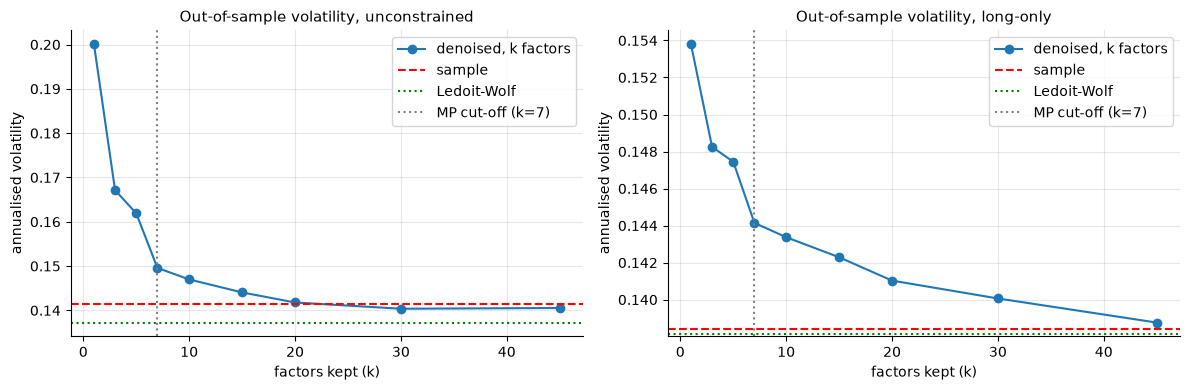

In [9]:
K_GRID = [1, 3, 5, 7, 10, 15, 20, 30, 45]
sweep = {"unconstrained": {k: [] for k in K_GRID}, "long-only": {k: [] for k in K_GRID}}
for i in rebal:
    win = returns.iloc[i - LOOKBACK:i]
    fwd = returns.iloc[i:i + HOLD]
    std = win.std().values
    ev_i, vec_i = qt.get_pca(np.corrcoef(win.values, rowvar=False))
    for k in K_GRID:
        cov_k = qt.corr2cov(qt.denoise_const_resid(ev_i, vec_i, k), std)
        sweep["unconstrained"][k].append(fwd @ qt.min_var_weights(cov_k))
        sweep["long-only"][k].append(fwd @ qt.min_var_long_only(cov_k))

sweep_vol = pd.DataFrame({
    kind: {k: pd.concat(v).std() * np.sqrt(252) for k, v in d.items()} for kind, d in sweep.items()})
base_vol = {"unconstrained": ret_free["sample"].std() * np.sqrt(252), "long-only": ret_lo["sample"].std() * np.sqrt(252)}
lw_vol = {"unconstrained": ret_free["ledoit-wolf"].std() * np.sqrt(252), "long-only": ret_lo["ledoit-wolf"].std() * np.sqrt(252)}
sweep_vol.index.name = "factors kept"
print(sweep_vol.round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, kind in zip(axes, sweep_vol):
    ax.plot(sweep_vol.index, sweep_vol[kind], "o-", label="denoised, k factors")
    ax.axhline(base_vol[kind], color="r", ls="--", label="sample")
    ax.axhline(lw_vol[kind], color="g", ls=":", label="Ledoit-Wolf")
    ax.axvline(n_facts, color="grey", ls=":", label=f"MP cut-off (k={n_facts})")
    ax.set(title=f"Out-of-sample volatility, {kind}", xlabel="factors kept (k)", ylabel="annualised volatility")
    ax.legend()
plt.tight_layout(); plt.show()

- Volatility falls steadily as more factors are kept. With 1 factor the unconstrained portfolio runs at 20.0%; at the noise cut-off (k = 7) 15.0%; at k = 20–30 it reaches 14.2–14.0%, the level of the sample matrix (14.1%).
- The noise cut-off discards real structure here: eigenvalues between 1.0 and 1.8 (PC8 onwards) carry sector information that is stable enough to help out of sample.
- Long-only shows the same direction over a much smaller range (15.4% to 13.9%), because the constraint already limits estimation damage.
- Ledoit-Wolf, which shrinks smoothly instead of cutting at a threshold, is the best unconstrained estimator (13.7%).

## 7 · Are the weights more stable?

A good covariance estimate should not make weights jump at each rebalance. Turnover is half the sum of absolute weight changes between consecutive unconstrained portfolios.

      sample  ledoit-wolf  denoised (const)
mean    0.45         0.33              0.27
50%     0.38         0.29              0.22
max     2.00         1.45              2.27


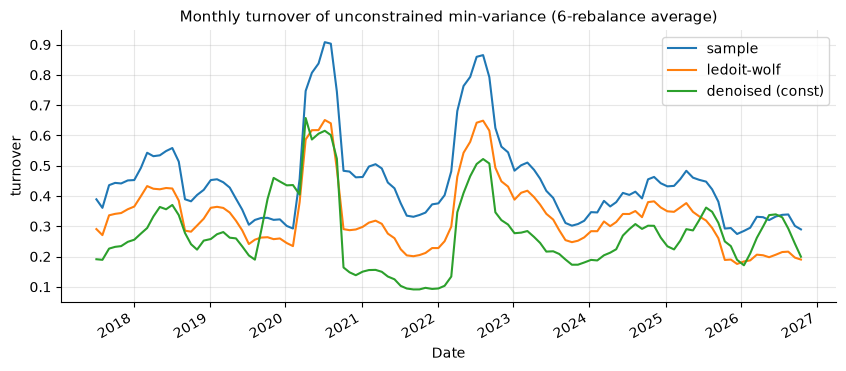

In [10]:
turn = {}
for m in methods_bt:
    ws = []
    for i in rebal:
        cov = cov_at(i, m)
        ws.append(qt.min_var_weights(cov))
    ws = np.array(ws)
    turn[m] = 0.5 * np.abs(np.diff(ws, axis=0)).sum(axis=1)
turn = pd.DataFrame(turn, index=returns.index[rebal][1:])
print(turn.describe().loc[["mean", "50%", "max"]].round(2).to_string())
turn.rolling(6).mean().plot(figsize=(10, 4), title="Monthly turnover of unconstrained min-variance (6-rebalance average)")
plt.ylabel("turnover"); plt.show()

- Average turnover is 0.27 for denoised weights against 0.45 for sample (Ledoit-Wolf 0.33): about 40% less trading.
- The saving is uneven. Denoised turnover spikes in 2020 (0.65 on the 6-rebalance average), and one rebalance reaches 2.27, above the sample maximum of 2.00.
- Costs are not charged in section 5, so the lower turnover is a real but unpriced advantage.

## 8 · Does denoising help when the estimation window is short?

The known-truth test used q = 2; the real test used q ≈ 5.6. Shorter windows react faster to regime changes but leave fewer observations per asset, which is where noise removal should matter. The same rolling minimum-variance test is repeated with 126-, 252- and 504-day windows (q ≈ 1.4, 2.8, 5.6) on one common out-of-sample period, so only the window length changes.

Common out-of-sample period: 2017-01-04 to 2026-10-29, 118 rebalances

Annualised out-of-sample volatility, unconstrained minimum variance
                    sample  ledoit-wolf  denoised (const)
126 days (q = 1.4)  0.2104       0.1334            0.1343
252 days (q = 2.8)  0.1522       0.1365            0.1495
504 days (q = 5.6)  0.1415       0.1372            0.1639

Average turnover per rebalance
                    sample  ledoit-wolf  denoised (const)
126 days (q = 1.4)   3.485        0.816             0.697
252 days (q = 2.8)   1.028        0.557             0.409
504 days (q = 5.6)   0.446        0.331             0.272


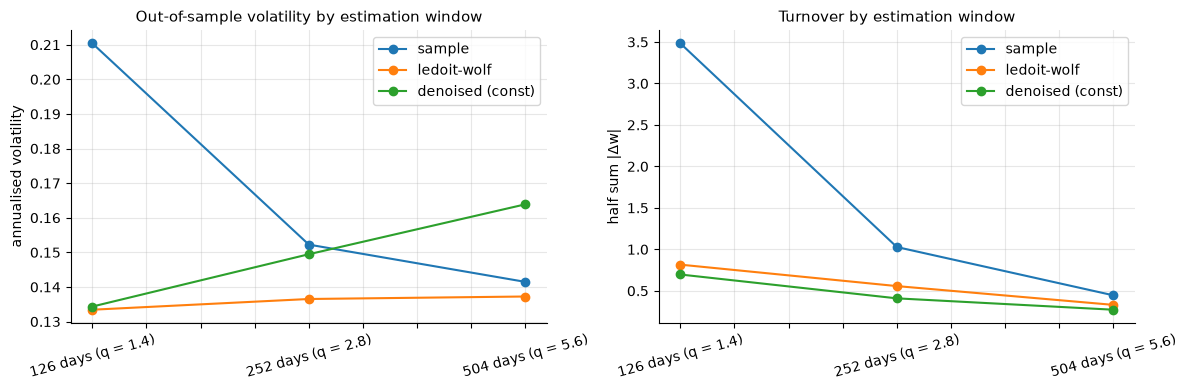

In [11]:
LB_GRID = [126, 252, 504]
reb_common = list(range(max(LB_GRID), len(returns) - 1, HOLD))
lb_vol, lb_turn = {}, {}
for lb in LB_GRID:
    rets_lb = {m: [] for m in methods_bt}
    w_prev, turn_lb = {m: None for m in methods_bt}, {m: [] for m in methods_bt}
    for i in reb_common:
        win = returns.iloc[i - lb:i].values
        fwd = returns.iloc[i:i + HOLD]
        for m in methods_bt:
            w = qt.min_var_weights(estimate(win, m))
            rets_lb[m].append(fwd @ w)
            if w_prev[m] is not None:
                turn_lb[m].append(0.5 * np.abs(w - w_prev[m]).sum())
            w_prev[m] = w
    key = f"{lb} days (q = {lb / returns.shape[1]:.1f})"
    lb_vol[key] = {m: pd.concat(v).std() * np.sqrt(252) for m, v in rets_lb.items()}
    lb_turn[key] = {m: np.mean(v) for m, v in turn_lb.items()}

lb_vol, lb_turn = pd.DataFrame(lb_vol).T, pd.DataFrame(lb_turn).T
print(f"Common out-of-sample period: {returns.index[reb_common[0]].date()} to {returns.index[-1].date()}, {len(reb_common)} rebalances")
print("\nAnnualised out-of-sample volatility, unconstrained minimum variance")
print(lb_vol.round(4).to_string())
print("\nAverage turnover per rebalance")
print(lb_turn.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
lb_vol.plot(ax=axes[0], marker="o")
axes[0].set(title="Out-of-sample volatility by estimation window", ylabel="annualised volatility", xlabel="")
lb_turn.plot(ax=axes[1], marker="o")
axes[1].set(title="Turnover by estimation window", ylabel="half sum |Δw|", xlabel="")
for ax in axes:
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

- **Short windows are where denoising pays.** With 126 days (q = 1.4, barely more days than stocks) the sample matrix is badly estimated: its minimum-variance portfolio runs at 21.0% volatility and turns over 3.5 times its value per rebalance. Denoising brings that to 13.4% and 0.70, level with Ledoit-Wolf (13.3%, 0.82).
- **The advantage fades as data grow.** At 252 days denoised volatility is 15.0% against 15.2% for the sample, a near tie; at 504 days it is 16.4% against 14.1%, the reversal of section 5. As the window lengthens, the sample matrix becomes reliable and the structure the noise cut-off removes starts to matter more than the noise it removes.
- **Turnover is lowest for denoising at every window** (0.70, 0.41 and 0.27), so its trading advantage holds even where its risk advantage does not.
- **Ledoit-Wolf is the steady choice:** the lowest volatility at every window (13.3%, 13.7% and 13.7%), with denoising within 0.1 pp of it only at 126 days.

## Conclusions

**What holds**
- The noise benchmark is correct, and with Gaussian block data denoising is a large improvement: optimised-portfolio risk falls from 41% to 10% above optimal, ahead of Ledoit-Wolf (24%).
- On real stocks denoising pays when the estimation window is short: with 126 days it cuts minimum-variance volatility from 21.0% to 13.4% and turnover from 3.5 to 0.7 per rebalance.
- Denoising makes the matrix better conditioned (197 → 43) and the weights calmer at every window length.
- Detoning exposes sector blocks (cross-sector correlation +0.16 → −0.04) and is the right preparation for clustering assets.

**What does not**
- With a 2-year window the noise cut-off keeps too few factors: realised risk rises (16.4% vs 14.1% sample), and 20–30 factors are needed to match the sample matrix. Equity noise is not Marcenko-Pastur noise.
- Ledoit-Wolf is the most robust estimator on this universe at every window (13.3–13.7%).

**Practical rule.** Use denoising, or Ledoit-Wolf, when the window holds fewer than about three days per asset (q below 3); with longer windows prefer Ledoit-Wolf, or tune the number of kept factors out of sample instead of trusting the noise cut-off. Use detoning for structure discovery, never for risk.

**Next steps.** Combine the two (denoise, then shrink the noise block toward its average with a Ledoit-Wolf weight); test a multi-asset universe, where a few clean factors are closer to the noise model; price the turnover difference with realistic costs.